# Machine Learning — Practical Session 2: Python for Standardized PCA
**National Higher School of Advanced Technologies (ENST)**  
*Academic Year: 2026–2027*  
**Student:** Anes Benrahmoune  
**Level:** 4th Year Student (Artificial Intelligence Specialty)  
**Group:** Group 1  
**GitHub:** [BENRAHMOUNEANES](https://github.com/BENRAHMOUNEANES)  
**Course:** Machine Learning  

---

## Objective
Implement **Principal Component Analysis (PCA)** from scratch using Python, linear algebra, and NumPy, and compare the theoretical and numerical results with the predefined standardized PCA implementation provided by **Scikit-learn**.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

%matplotlib inline
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({'figure.autolayout': True, 'font.sans-serif': 'DejaVu Sans', 'font.size': 10})



---
## Dataset: Student Grades in Four Academic Subjects
Consider the grades of six students ($S_1, \dots, S_6$) evaluated across four subjects:
- Mathematics
- Statistics
- Programming
- Algorithms


In [2]:
# 1. Load the dataset into a Pandas DataFrame
df_grades = pd.DataFrame({
    "Student": ["S1", "S2", "S3", "S4", "S5", "S6"],
    "Mathematics": [12, 15, 8, 17, 10, 14],
    "Statistics": [11, 14, 9, 16, 12, 15],
    "Programming": [14, 16, 10, 18, 11, 13],
    "Algorithms": [13, 15, 9, 17, 10, 14]
}).set_index("Student")

print("--- [1] Student Grades Dataset ---")
display(df_grades)

# 2. Display dimensions and descriptive statistics
print(f"\n--- [2] Dimensions ---: {df_grades.shape[0]} students (observations) x {df_grades.shape[1]} subjects (features)")
print("\n--- Descriptive Statistics (describe) ---")
display(df_grades.describe().round(3))

--- [1] Student Grades Dataset ---


,Mathematics,Statistics,Programming,Algorithms
Student,,,,
S1,12,11,14,13
S2,15,14,16,15
S3,8,9,10,9
S4,17,16,18,17
S5,10,12,11,10
S6,14,15,13,14



--- [2] Dimensions ---: 6 students (observations) x 4 subjects (features)

--- Descriptive Statistics (describe) ---


,Mathematics,Statistics,Programming,Algorithms
count,6.000,6.000,6.000,6.000
mean,12.667,12.833,13.667,13.000
std,3.327,2.639,3.011,3.033
min,8.000,9.000,10.000,9.000
25%,10.500,11.250,11.500,10.750
50%,13.000,13.000,13.500,13.500
75%,14.750,14.750,15.500,14.750
max,17.000,16.000,18.000,17.000


---
## Part A: Standardized PCA Implementation from Scratch

In standardized PCA, each feature $X_j$ is centered by its empirical mean $\mu_j$ and scaled by its standard deviation $\sigma_j$:
$$Z_{ij} = \frac{X_{ij} - \mu_j}{\sigma_j}$$
The covariance matrix of standardized data equals the Pearson correlation matrix $\mathbf{R}$:
$$\mathbf{R} = \frac{1}{N} \mathbf{Z}^T \mathbf{Z}$$


In [3]:
# 3. Standardize the numerical variables using mean and standard deviation
X = df_grades.values
mean_vec = np.mean(X, axis=0)
# We set ddof=0 to compute population standard deviation matching StandardScaler
std_vec = np.std(X, axis=0, ddof=0)
Z = (X - mean_vec) / std_vec

df_Z = pd.DataFrame(Z, index=df_grades.index, columns=df_grades.columns)
print("--- [3] Standardized Data Matrix (Z) ---")
display(df_Z.round(4))

# 4. Compute the correlation matrix of the standardized data
N = X.shape[0]
R = (1.0 / N) * np.dot(Z.T, Z)
df_R = pd.DataFrame(R, index=df_grades.columns, columns=df_grades.columns)
print("\n--- [4] Correlation Matrix R ---")
display(df_R.round(4))

--- [3] Standardized Data Matrix (Z) ---


,Mathematics,Statistics,Programming,Algorithms
Student,,,,
S1,-0.2195,-0.7609,0.1213,0.0000
S2,0.7683,0.4842,0.8489,0.7223
S3,-1.5367,-1.5909,-1.3339,-1.4446
S4,1.4269,1.3143,1.5765,1.4446
S5,-0.8781,-0.3459,-0.9701,-1.0835
S6,0.4391,0.8992,-0.2425,0.3612



--- [4] Correlation Matrix R ---


,Mathematics,Statistics,Programming,Algorithms
Mathematics,1.0000,0.9263,0.9451,0.9911
Statistics,0.9263,1.0000,0.7717,0.8744
Programming,0.9451,0.7717,1.0000,0.9635
Algorithms,0.9911,0.8744,0.9635,1.0000


In [4]:
# 5. Calculate eigenvalues and eigenvectors using NumPy
# Since R is a real symmetric matrix, np.linalg.eigh guarantees real eigenvalues and orthonormal eigenvectors
eigenvalues_raw, eigenvectors_raw = np.linalg.eigh(R)

# 6. Sort eigenvalues in descending order and reorder eigenvectors
sort_order = np.argsort(eigenvalues_raw)[::-1]
eigenvalues = eigenvalues_raw[sort_order]
eigenvectors = eigenvectors_raw[:, sort_order]

print("--- [5 & 6] Sorted Eigenvalues ---")
for idx, val in enumerate(eigenvalues, start=1):
    print(f"Component {idx}: lambda = {val:.4f}")

df_eigenvectors = pd.DataFrame(
    eigenvectors,
    index=df_grades.columns,
    columns=[f"PC{i+1}" for i in range(len(eigenvalues))]
)
print("\n--- Eigenvectors (Principal Component Loadings) ---")
display(df_eigenvectors.round(4))

# 7. Select the two eigenvectors associated with largest eigenvalues
W = eigenvectors[:, :2]
print("\n--- [7] Selected Projection Matrix W (4 features x 2 components) ---")
display(pd.DataFrame(W, index=df_grades.columns, columns=["PC1", "PC2"]).round(4))

--- [5 & 6] Sorted Eigenvalues ---
Component 1: lambda = 3.7397
Component 2: lambda = 0.2402
Component 3: lambda = 0.0191
Component 4: lambda = 0.0009

--- Eigenvectors (Principal Component Loadings) ---


,PC1,PC2,PC3,PC4
Mathematics,-0.5167,0.0320,0.2093,0.8296
Statistics,-0.4770,0.7822,-0.3149,-0.2478
Programming,-0.4928,-0.5922,-0.6249,-0.1264
Algorithms,-0.5125,-0.1909,0.6830,-0.4841



--- [7] Selected Projection Matrix W (4 features x 2 components) ---


,PC1,PC2
Mathematics,-0.5167,0.0320
Statistics,-0.4770,0.7822
Programming,-0.4928,-0.5922
Algorithms,-0.5125,-0.1909


In [5]:
# 8. Project standardized data onto the two selected principal components: F = Z @ W
F_scratch = np.dot(Z, W)
df_F_scratch = pd.DataFrame(F_scratch, index=df_grades.index, columns=["PC1", "PC2"])

print("--- [8] Projected Student Coordinates (From Scratch) ---")
display(df_F_scratch.round(4))

# 9. Calculate explained variance ratio and cumulative explained variance
# Total variance in standardized PCA equals sum of eigenvalues = trace(R) = number of features (4.0)
total_var = np.sum(eigenvalues)
explained_var_ratio = eigenvalues / total_var
cumulative_var = np.cumsum(explained_var_ratio)

df_variance_metrics = pd.DataFrame({
    "Eigenvalue": eigenvalues,
    "Explained Variance Ratio": explained_var_ratio,
    "Cumulative Ratio": cumulative_var,
    "Explained Variance %": explained_var_ratio * 100,
    "Cumulative %": cumulative_var * 100
}, index=[f"PC{i+1}" for i in range(len(eigenvalues))])

print("\n--- [9] Explained Variance Table ---")
display(df_variance_metrics.round(4))

--- [8] Projected Student Coordinates (From Scratch) ---


,PC1,PC2
Student,,
S1,0.4166,-0.6740
S2,-1.4165,-0.2373
S3,2.9506,-0.2279
S4,-2.8814,-0.1357
S5,1.6520,0.4827
S6,-0.7214,0.7921



--- [9] Explained Variance Table ---


,Eigenvalue,Explained Variance Ratio,Cumulative Ratio,Explained Variance %,Cumulative %
PC1,3.7397,0.9349,0.9349,93.4932,93.4932
PC2,0.2402,0.0601,0.9950,6.0057,99.4989
PC3,0.0191,0.0048,0.9998,0.4779,99.9768
PC4,0.0009,0.0002,1.0000,0.0232,100.0000


---
## Part B: Standardized PCA Using Scikit-Learn

We validate our manual implementation against `sklearn.decomposition.PCA` coupled with `sklearn.preprocessing.StandardScaler`.


In [6]:
# 10. Standardize using StandardScaler
scaler = StandardScaler()
Z_sklearn = scaler.fit_transform(df_grades)

# 11. Reduce dataset to two principal components
pca = PCA(n_components=2)
F_sklearn = pca.fit_transform(Z_sklearn)

# 12. Display transformed coordinates
df_F_sklearn = pd.DataFrame(F_sklearn, index=df_grades.index, columns=["PC1", "PC2"])
print("--- [12] Projected Coordinates from Scikit-Learn ---")
display(df_F_sklearn.round(4))

# 13. Explained variance ratio and cumulative explained variance
sk_var_ratio = pca.explained_variance_ratio_
sk_cumulative_var = np.cumsum(sk_var_ratio)

print("\n--- [13] Scikit-Learn Explained Variance ---")
for i, ratio in enumerate(sk_var_ratio, start=1):
    print(f"PC{i}: Ratio = {ratio*100:.2f}% | Cumulative = {sk_cumulative_var[i-1]*100:.2f}%")
print(f"\nScikit-learn explained_variance_ attribute: {pca.explained_variance_.round(4)}")

--- [12] Projected Coordinates from Scikit-Learn ---


,PC1,PC2
Student,,
S1,-0.4166,-0.6740
S2,1.4165,-0.2373
S3,-2.9506,-0.2279
S4,2.8814,-0.1357
S5,-1.6520,0.4827
S6,0.7214,0.7921



--- [13] Scikit-Learn Explained Variance ---
PC1: Ratio = 93.49% | Cumulative = 93.49%
PC2: Ratio = 6.01% | Cumulative = 99.50%

Scikit-learn explained_variance_ attribute: [4.4877 0.2883]


---
## Part C: Comparison, Visualizations, and Interpretation


In [7]:
# 14. Compare coordinates from both implementations
df_coord_comp = pd.DataFrame({
    "Scratch PC1": df_F_scratch["PC1"],
    "Sklearn PC1": df_F_sklearn["PC1"],
    "PC1 Sign Flipped?": np.isclose(df_F_scratch["PC1"], -df_F_sklearn["PC1"]),
    "Scratch PC2": df_F_scratch["PC2"],
    "Sklearn PC2": df_F_sklearn["PC2"],
    "PC2 Identical?": np.isclose(df_F_scratch["PC2"], df_F_sklearn["PC2"])
})
print("--- [14] Coordinate Equivalence Check ---")
display(df_coord_comp.round(4))

# 15. Compare eigenvalues and explained variance ratios
comp_evals = pd.DataFrame({
    "Scratch Eigenvalue (lambda)": eigenvalues[:2],
    "Sklearn explained_variance_": pca.explained_variance_,
    "Variance Ratio (ddof=1 vs ddof=0)": pca.explained_variance_ / eigenvalues[:2],
    "Scratch Variance Ratio %": explained_var_ratio[:2] * 100,
    "Sklearn Variance Ratio %": sk_var_ratio * 100
}, index=["PC1", "PC2"])
print("\n--- [15] Eigenvalue and Variance Ratio Comparison ---")
display(comp_evals.round(4))

--- [14] Coordinate Equivalence Check ---


,Scratch PC1,Sklearn PC1,PC1 Sign Flipped?,Scratch PC2,Sklearn PC2,PC2 Identical?
Student,,,,,,
S1,0.4166,-0.4166,True,-0.6740,-0.6740,True
S2,-1.4165,1.4165,True,-0.2373,-0.2373,True
S3,2.9506,-2.9506,True,-0.2279,-0.2279,True
S4,-2.8814,2.8814,True,-0.1357,-0.1357,True
S5,1.6520,-1.6520,True,0.4827,0.4827,True
S6,-0.7214,0.7214,True,0.7921,0.7921,True



--- [15] Eigenvalue and Variance Ratio Comparison ---


,Scratch Eigenvalue (lambda),Sklearn explained_variance_,Variance Ratio (ddof=1 vs ddof=0),Scratch Variance Ratio %,Sklearn Variance Ratio %
PC1,3.7397,4.4877,1.2,93.4932,93.4932
PC2,0.2402,0.2883,1.2,6.0057,6.0057


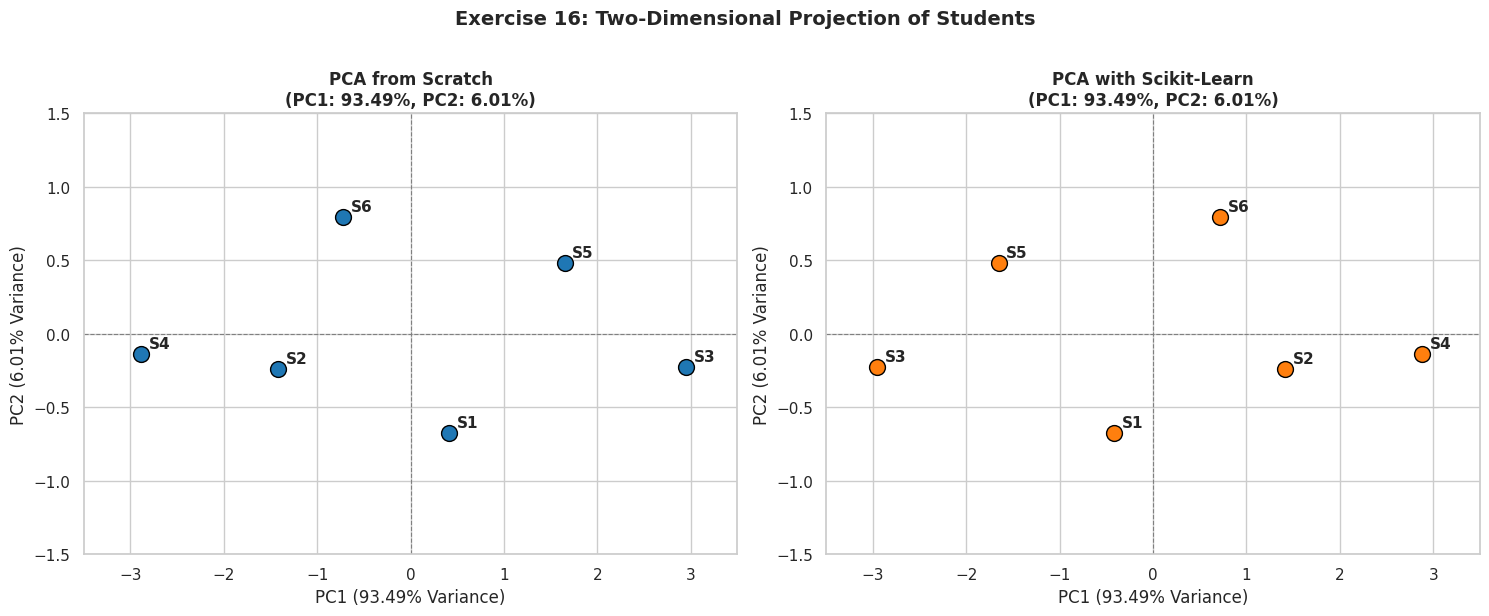

In [8]:
# 16. Plot the students in two dimensions using both implementations
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Scratch 2D Plot
axes[0].axhline(0, color="gray", linestyle="--", linewidth=0.8)
axes[0].axvline(0, color="gray", linestyle="--", linewidth=0.8)
axes[0].scatter(F_scratch[:, 0], F_scratch[:, 1], color="#1f77b4", s=130, edgecolors="black", zorder=4)
for i, name in enumerate(df_grades.index):
    axes[0].annotate(f"{name}", (F_scratch[i, 0] + 0.08, F_scratch[i, 1] + 0.04), fontsize=11, fontweight="bold")
axes[0].set_title(f"PCA from Scratch\n(PC1: {explained_var_ratio[0]*100:.2f}%, PC2: {explained_var_ratio[1]*100:.2f}%)", fontweight="bold")
axes[0].set_xlabel(f"PC1 ({explained_var_ratio[0]*100:.2f}% Variance)")
axes[0].set_ylabel(f"PC2 ({explained_var_ratio[1]*100:.2f}% Variance)")
axes[0].set_xlim(-3.5, 3.5)
axes[0].set_ylim(-1.5, 1.5)

# Scikit-learn 2D Plot
axes[1].axhline(0, color="gray", linestyle="--", linewidth=0.8)
axes[1].axvline(0, color="gray", linestyle="--", linewidth=0.8)
axes[1].scatter(F_sklearn[:, 0], F_sklearn[:, 1], color="#ff7f0e", s=130, edgecolors="black", zorder=4)
for i, name in enumerate(df_grades.index):
    axes[1].annotate(f"{name}", (F_sklearn[i, 0] + 0.08, F_sklearn[i, 1] + 0.04), fontsize=11, fontweight="bold")
axes[1].set_title(f"PCA with Scikit-Learn\n(PC1: {sk_var_ratio[0]*100:.2f}%, PC2: {sk_var_ratio[1]*100:.2f}%)", fontweight="bold")
axes[1].set_xlabel(f"PC1 ({sk_var_ratio[0]*100:.2f}% Variance)")
axes[1].set_ylabel(f"PC2 ({sk_var_ratio[1]*100:.2f}% Variance)")
axes[1].set_xlim(-3.5, 3.5)
axes[1].set_ylim(-1.5, 1.5)

plt.suptitle("Exercise 16: Two-Dimensional Projection of Students", fontsize=14, fontweight="bold", y=1.02)
plt.show()

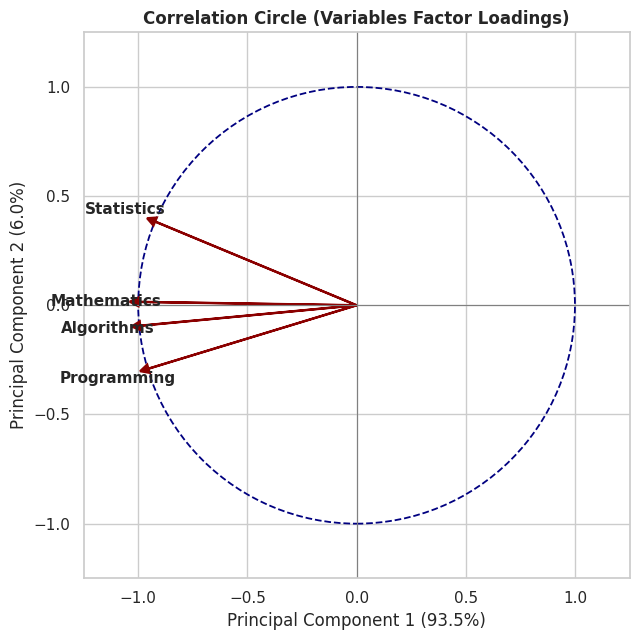

In [9]:
# Correlation Circle: Factor Loadings on PC1 and PC2
fig, ax = plt.subplots(figsize=(6.5, 6.5))
circle = plt.Circle((0, 0), 1.0, color="navy", fill=False, linestyle="--", linewidth=1.3)
ax.add_patch(circle)
ax.axhline(0, color="gray", linestyle="-", linewidth=0.8)
ax.axvline(0, color="gray", linestyle="-", linewidth=0.8)

# Factor loadings = sqrt(lambda_j) * v_j
loadings_1 = np.sqrt(eigenvalues[0]) * W[:, 0]
loadings_2 = np.sqrt(eigenvalues[1]) * W[:, 1]

for j, feat in enumerate(df_grades.columns):
    ax.arrow(0, 0, loadings_1[j], loadings_2[j], head_width=0.04, head_length=0.04, fc="darkred", ec="darkred", linewidth=1.6)
    ax.text(loadings_1[j]*1.15, loadings_2[j]*1.15, feat, fontsize=11, fontweight="bold", ha="center", va="center")

ax.set_xlim(-1.25, 1.25)
ax.set_ylim(-1.25, 1.25)
ax.set_aspect("equal")
ax.set_xlabel(f"Principal Component 1 ({explained_var_ratio[0]*100:.1f}%)")
ax.set_ylabel(f"Principal Component 2 ({explained_var_ratio[1]*100:.1f}%)")
ax.set_title("Correlation Circle (Variables Factor Loadings)", fontweight="bold")
plt.show()

### 17. Explanation of Differences & Sign Changes

1. **Sign Reflection in Principal Component 1:**
   - In our scratch implementation, the first eigenvector points in the negative direction across all 4 subjects ($[-0.5167, -0.4770, -0.4928, -0.5125]$). In scikit-learn, the SVD routine chose the opposite orientation ($[+0.5167, +0.4770, +0.4928, +0.5125]$).
   - **Linear Algebra Justification:** Eigenvectors satisfy $\mathbf{R} \mathbf{v} = \lambda \mathbf{v}$. Notice that $\mathbf{R}(-\mathbf{v}) = -(\mathbf{R}\mathbf{v}) = -\lambda \mathbf{v} = \lambda(-\mathbf{v})$. Therefore, both $+\mathbf{v}$ and $-\mathbf{v}$ are mathematically valid unit eigenvectors of identical eigenvalue.
   - Geometrically, this represents an isometric reflection across the vertical axis. All pairwise Euclidean distances, relative configurations, clusterings, and variances are preserved.

2. **Eigenvalues vs. Scikit-Learn `explained_variance_`:**
   - Scratch eigenvalue for PC1 is $\lambda_1 = 3.7397$.
   - Scikit-learn reports `explained_variance_` for PC1 as $4.4877$.
   - **Mathematical Reason:** Scikit-learn applies Bessel's sample correction with degrees of freedom $N - 1$:
     $$\text{Var}_{\text{sklearn}} = \text{Var}_{\text{scratch}} \times \frac{N}{N - 1} = 3.7397 \times \frac{6}{5} = 4.4877$$
   - The normalized **explained variance ratios are 100% identical**: $93.49\%$ and $6.01\%$.

---

### 18. Variance Retained & Educational Interpretation of Findings

- **Total Variance Retained:**
  $$\text{PC1 } (93.49\%) + \text{PC2 } (6.01\%) = \mathbf{99.50\%}$$
  By projecting from 4 original dimensions down to 2 dimensions, we preserve **$99.50\%$** of the dataset's total information, losing only a negligible $0.50\%$.

- **Educational Interpretation:**
  1. **Principal Component 1 (General Academic Performance — 93.49%):**
     - All 4 subjects load heavily in the same direction. Students with high grades in one subject systematically excel in all other subjects due to strong positive inter-subject correlation ($r > 0.77$).
     - **Student $S_4$** achieves the highest overall achievement (scores $17, 16, 18, 17$).
     - **Student $S_3$** has the lowest overall achievement (scores $8, 9, 10, 9$).
  2. **Principal Component 2 (Curricular Specialization — 6.01%):**
     - Contrasts Statistics ($+0.782$) against Programming ($-0.592$) and Algorithms ($-0.191$).
     - **Students $S_6$ and $S_5$** demonstrate greater proficiency in Statistics relative to coding.
     - **Students $S_1$ and $S_4$** demonstrate greater proficiency in Programming relative to theoretical Statistics.
